In [3]:

# 1. Import packages
import tensorflow as tf
from tensorflow import keras
from keras.datasets import mnist
from keras import layers
import matplotlib.pyplot as plt

X_train: (60000, 28, 28)
Y_train: (60000,)
X_test: (10000, 28, 28)
Y_test: (10000,)


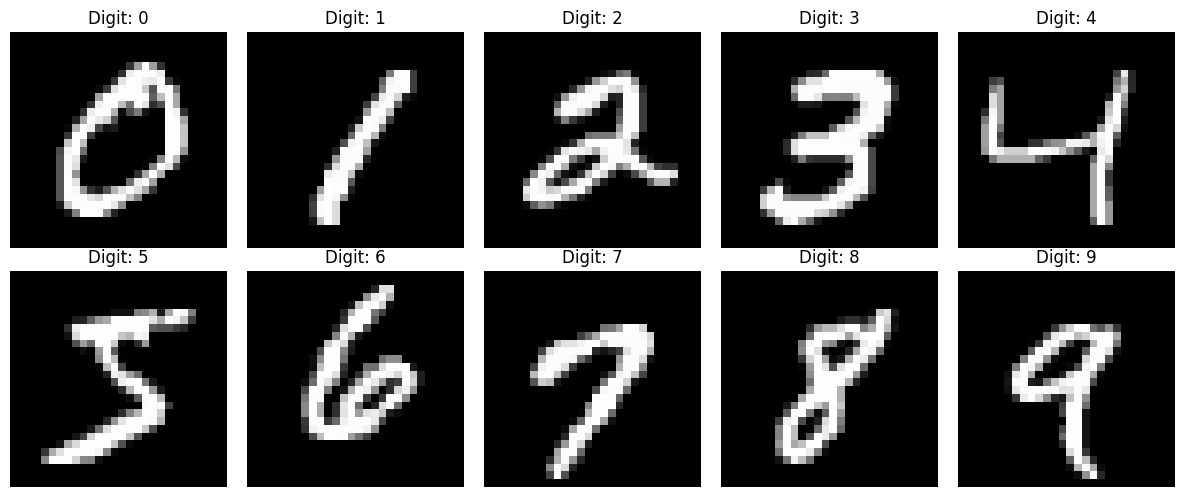

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8296 - loss: 0.6834 - val_accuracy: 0.9148 - val_loss: 0.3251
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9018 - loss: 0.3520 - val_accuracy: 0.9312 - val_loss: 0.2616
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9153 - loss: 0.3004 - val_accuracy: 0.9352 - val_loss: 0.2298
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9243 - loss: 0.2696 - val_accuracy: 0.9420 - val_loss: 0.2107
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9307 - loss: 0.2465 - val_accuracy: 0.9470 - val_loss: 0.1938
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9363 - loss: 0.2269
Test Loss: 0.2268882840871811
Test Accuracy: 0.9362999796867371


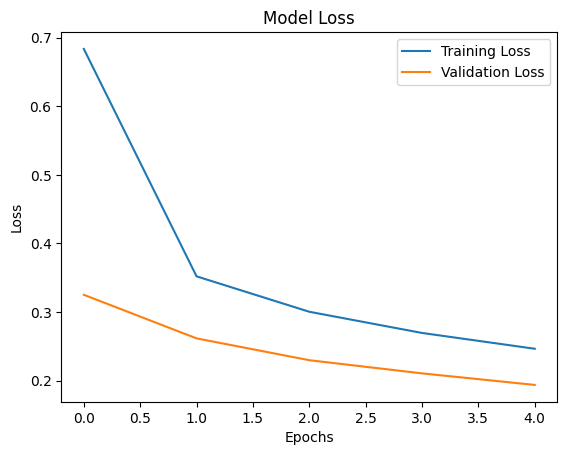

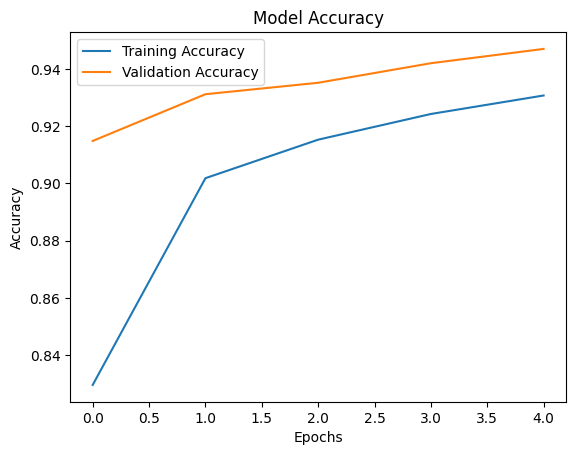

In [7]:

# Practical 2: Feedforward Neural Network using Keras and TensorFlow


# 2. Load MNIST dataset
(train_X, train_y), (test_X, test_y) = mnist.load_data()

# 3. Display dataset shapes
print("X_train:", train_X.shape)
print("Y_train:", train_y.shape)
print("X_test:", test_X.shape)
print("Y_test:", test_y.shape)


# 4. Display handwritten digits in ascending order (0-9)

plt.figure(figsize=(12, 5))

for digit in range(10):

    index = (train_y == digit).nonzero()[0][0]

    plt.subplot(2, 5, digit + 1)
    plt.imshow(train_X[index], cmap='gray')
    plt.title("Digit: " + str(digit))
    plt.axis('off')

plt.tight_layout()
plt.show()



# 5. Normalize the data
train_X = train_X / 255.0
test_X = test_X / 255.0

# 6. Define Feedforward Neural Network
model = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Display model architecture
model.summary()

# 7. Compile model using SGD
model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 8. Train the model
history = model.fit(
    train_X,
    train_y,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

# 9. Evaluate the model
test_loss, test_accuracy = model.evaluate(test_X, test_y)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 10. Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# 11. Plot training accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
